## **Проектная работа №1: Классификация объектов на изображении**









### **Цель:**


Разработать программу на Python, которая принимает на вход фотографию с изображением монет и вычисляет общую сумму денежных средств, отображенных на ней, используя только библиотеку OpenCV и стандартные библиотеки Python.


### **Базовая реализация:**



1. **Сбор изображения:**
   - Используйте камеру или загрузите готовое изображение с монетами для обработки.

2. **Предварительная обработка изображения:**
   - Преобразуйте изображение в оттенки серого.
   - Примените размытие Гаусса для уменьшения шума.
   - Используйте оператор Кэнни для обнаружения краев.

3. **Обнаружение кругов (монет):**
   - Используйте преобразование Хафа для обнаружения кругов на изображении.
   - Получите координаты центров и радиусов обнаруженных кругов (монет).

4. **Классификация монет:**
   - Определите номинал каждой монеты на основе ее радиуса.
   - Установите пороговые значения для радиусов, соответствующие разным номиналам:
     - **Маленький радиус:** 1 рубль.
     - **Средний радиус:** 2 рубля.
     - **Большой радиус:** 5 рублей.

5. **Подсчет общей суммы:**
   - Суммируйте номиналы всех обнаруженных монет.
   - Отобразите общую сумму на изображении или в консоли.

6. **Отображение результатов:**
   - Нарисуйте окружности на изображении вокруг обнаруженных монет.
   - Подпишите рядом с каждой монетой ее номинал.
   - Покажите исходное изображение с отмеченными монетами.
   - Выведите обработанные этапы для визуализации процесса (например, изображение после предварительной обработки, с контурами и т.д.).



### **Требования к реализации:**



- Использовать только библиотеку **OpenCV** и стандартные библиотеки Python (например, **NumPy**).
- Код должен быть хорошо документирован с комментариями для каждого основного блока.
- Предусмотреть возможность настройки параметров обработки через трекбары или отдельные переменные.



### **Рекомендации:**




- **Преобразование Хафа** для кругов является удобным инструментом для обнаружения круглых объектов на изображении.
- **Пороговые значения радиусов** необходимо подобрать экспериментально, протестировав на образцах монет разных номиналов.
- **Обработка перекрывающихся монет** может потребовать более сложных алгоритмов, таких как водоразделение или использование градиентных признаков.
- Тестируйте программу на различных изображениях с разным количеством и расположением монет, а также при разном освещении.





### **Ожидаемый результат:**




В результате выполнения задания вы получите программу, которая способна:

- Принимать на вход изображение с монетами.
- Обрабатывать изображение и обнаруживать монеты без использования библиотеки cvzone.
- Определять номинал каждой монеты на основе ее радиуса или других признаков.
- Вычислять и отображать общую сумму монет на изображении.



---

**Пример использования программы:**

- Пользователь запускает программу.
- Загружается изображение с монетами.
- Программа обрабатывает изображение, отмечает каждую монету и подписывает ее номинал.
- Отображается изображение с результатами и выводится общая сумма, например: **"Общая сумма: 37 рублей"**.



---

**Заметка:**

Данный проект позволит вам:

- Изучить и применить технологии обработки изображений с помощью OpenCV без привлечения сторонних библиотек.
- Научиться решать практические задачи компьютерного зрения, применяя базовые методы и улучшая их по мере необходимости.




---

**Советы по реализации:**

- **Настройка параметров:**
  - Для преобразования Хафа используйте функцию `cv2.HoughCircles()`.
  - Экспериментируйте с параметрами `dp`, `minDist`, `param1`, `param2`, `minRadius`, `maxRadius`.
- **Отображение результатов:**
  - Используйте функцию `cv2.circle()` для рисования окружностей.
  - Для отображения текста воспользуйтесь `cv2.putText()`.
- **Обработка ошибок:**
  - Обрабатывайте случаи, когда преобразование Хафа не обнаруживает ни одной монеты.
  - Предусмотрите проверку входных данных и вывод информативных сообщений для пользователя.

### Выполнение работы

Использую два изображения с монетами 1, 2 и 5 рублей.
На каждом изображении сумма равна 8 рублям.

Источники изображений: [первое](https://filtorg.ru/images/thumbnails/634/554/detailed/87/20250506_101409-Photoroom.png), [второе](https://auction.conros.ru/img/488/2255+.jpg).

In [1]:
from pathlib import Path
from urllib.request import Request, urlopen
from urllib.parse import quote
import cv2
import numpy as np

# Эти функции нужны только для показа изображений в ноутбуке.
from IPython.display import Image, display


def show_image(image, extension='.jpg'):
    # Уменьшаем только картинку для вывода, расчёты делаем в исходном размере.
    height, width = image.shape[:2]
    if width > 1000:
        image = cv2.resize(image, (1000, round(height * 1000 / width)))
    success, buffer = cv2.imencode(extension, image)
    if success:
        display(Image(data=buffer.tobytes()))


# При запуске в Colab загружаем фотографии из своего репозитория.
folder = Path('images')
folder.mkdir(exist_ok=True)
image_names = ['coins_1.png', 'coins_2.jpg']

for name in image_names:
    path = folder / name
    if not path.exists():
        url = 'https://raw.githubusercontent.com/German121/image_processing/main/'
        url += quote('Задание 3/images/' + name)
        try:
            request = Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urlopen(request, timeout=30) as response:
                path.write_bytes(response.read())
        except OSError as error:
            print('Не удалось загрузить', name, ':', error)

### Параметры обработки

Пороги подобрал по радиусам найденных монет. Для первого снимка границы —
116 и 131 пиксель, для второго — 169 и 187 пикселей.
Радиус меньше первой границы — 1 рубль, между границами — 2 рубля,
от второй границы — 5 рублей. Для снимка с другим масштабом пороги нужно изменить.

In [2]:
# Параметры размытия и поиска границ.
blur_size = (5, 5)
canny_low = 50
canny_high = 100

# Параметры преобразования Хафа.
dp = 1.2
min_distance = 180
param1 = canny_high
param2 = 100
min_radius = 90
max_radius = 220

# Границы радиусов для монет 1, 2 и 5 рублей.
radius_limits = {
    'coins_1.png': (116, 131),
    'coins_2.jpg': (169, 187),
}

### Поиск монет и подсчёт суммы

In [3]:
def count_coins(image_path, radius_1, radius_2, show_steps=True):
    # Читаем изображение и проверяем файл.
    if not Path(image_path).is_file():
        print('Файл не найден:', image_path)
        return None

    image = cv2.imread(str(image_path))
    if image is None:
        print('Не удалось открыть изображение:', image_path)
        return None

    # Переводим в серый цвет, размываем и выделяем границы.
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, blur_size, 0)
    edges = cv2.Canny(blurred, canny_low, canny_high)

    # HoughCircles получает размытое изображение и сам ищет на нём границы.
    circles = cv2.HoughCircles(
        blurred, cv2.HOUGH_GRADIENT, dp, min_distance,
        param1=param1, param2=param2,
        minRadius=min_radius, maxRadius=max_radius
    )

    result = image.copy()
    values = []

    if circles is None:
        print('Монеты не найдены.')
    else:
        circles = np.round(circles[0]).astype(int)
        circles = sorted(circles, key=lambda coin: coin[0])

        # Определяем номинал каждой монеты по радиусу.
        for number, (x, y, radius) in enumerate(circles, start=1):
            if radius < radius_1:
                value = 1
            elif radius < radius_2:
                value = 2
            else:
                value = 5

            values.append(value)
            print(f'Монета {number}: центр ({x}, {y}), радиус {radius} пкс, {value} руб.')

            # Отмечаем окружность, центр и номинал.
            cv2.circle(result, (x, y), radius, (0, 180, 0), 3)
            cv2.circle(result, (x, y), 3, (0, 0, 255), -1)
            cv2.putText(result, f'{value} rub', (x - 55, y - 35),
                        cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 200), 3)

    # Складываем номиналы и выводим результат.
    total = sum(values)
    print('Найдено монет:', len(values))
    print('Общая сумма:', total, 'руб.')
    cv2.putText(result, f'Total: {total} rub', (15, 35),
                cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 200), 2)

    if show_steps:
        print('Исходное изображение')
        show_image(image)
        print('Слева направо: оттенки серого, размытие Гаусса, границы Кэнни')
        show_image(cv2.hconcat([gray, blurred, edges]), '.png')

    print('Результат')
    show_image(result)
    return values

coins_1.png
Монета 1: центр (191, 410), радиус 124 пкс, 2 руб.
Монета 2: центр (326, 141), радиус 138 пкс, 5 руб.
Монета 3: центр (459, 409), радиус 109 пкс, 1 руб.
Найдено монет: 3
Общая сумма: 8 руб.
Исходное изображение


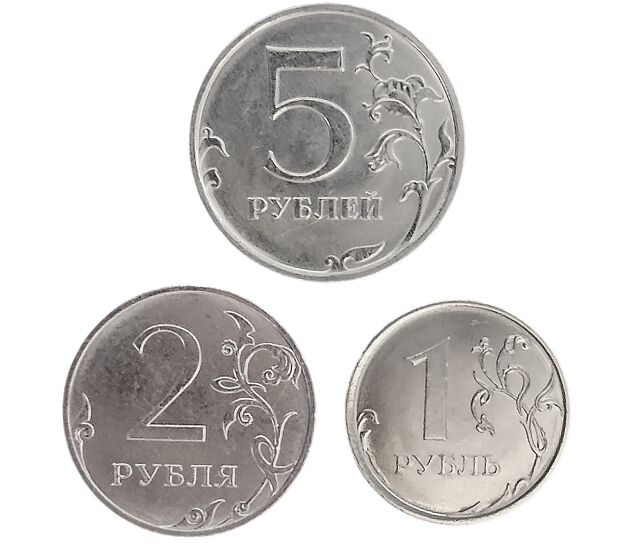

Слева направо: оттенки серого, размытие Гаусса, границы Кэнни


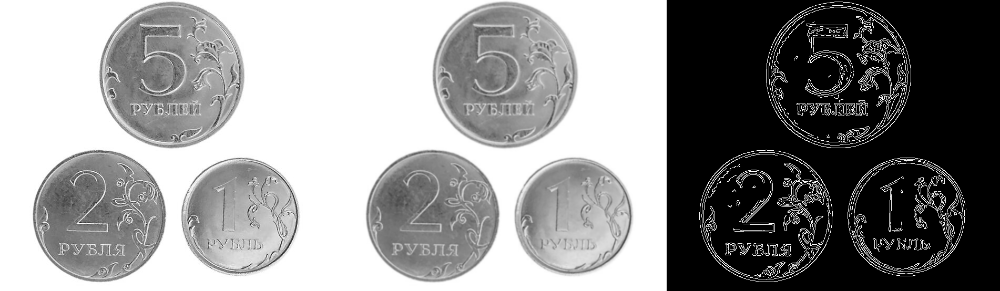

Результат


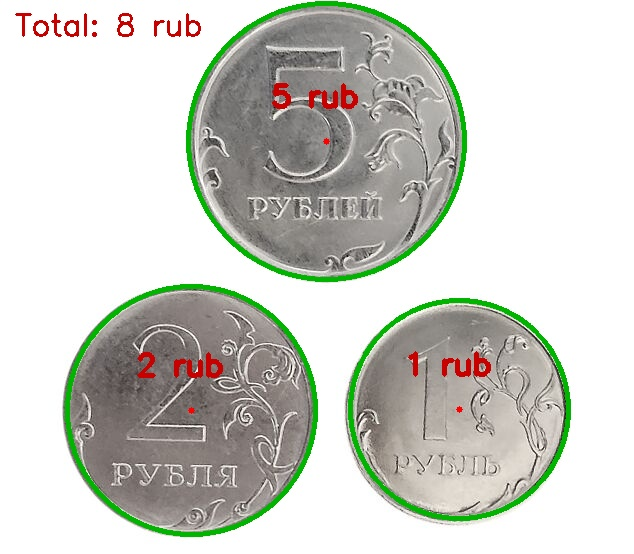

Сумма совпала с проверкой вручную: True

coins_2.jpg
Монета 1: центр (185, 231), радиус 160 пкс, 1 руб.
Монета 2: центр (565, 230), радиус 178 пкс, 2 руб.
Монета 3: центр (944, 220), радиус 195 пкс, 5 руб.
Найдено монет: 3
Общая сумма: 8 руб.
Исходное изображение


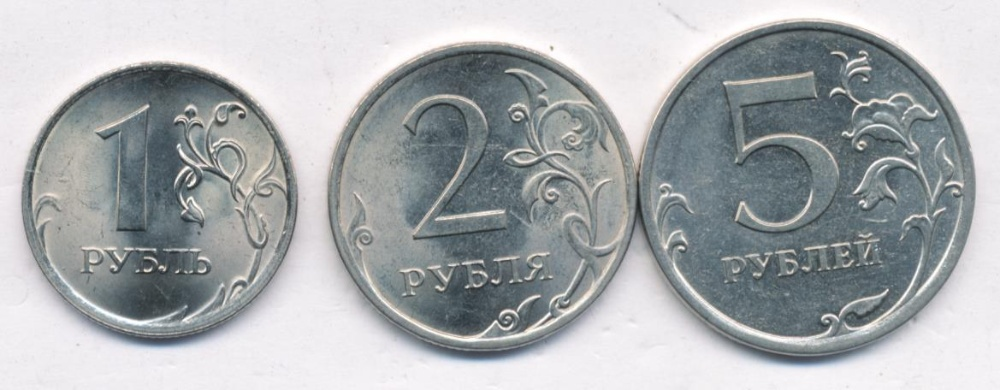

Слева направо: оттенки серого, размытие Гаусса, границы Кэнни


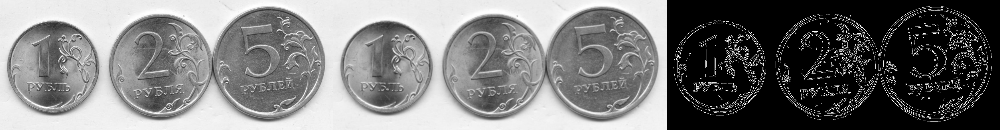

Результат


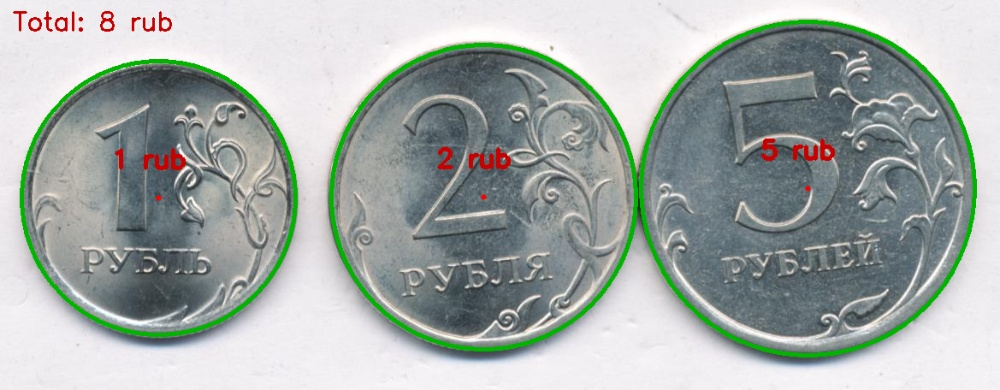

Сумма совпала с проверкой вручную: True



In [4]:
for name in image_names:
    print(name)
    radius_1, radius_2 = radius_limits[name]
    values = count_coins(folder / name, radius_1, radius_2)
    if values is not None:
        print('Сумма совпала с проверкой вручную:', sum(values) == 8)
    print()

На первом снимке найдены радиусы 124, 138 и 109 пикселей,
на втором — 160, 178 и 195 пикселей. На обоих снимках найдены все три монеты.
Сумма совпала с подсчётом вручную: 1 + 2 + 5 = 8 рублей.

### Проверка при меньшей яркости

Уменьшу яркость первого снимка до 65% и оставлю те же параметры.

Монета 1: центр (188, 411), радиус 126 пкс, 2 руб.
Монета 2: центр (326, 142), радиус 138 пкс, 5 руб.
Монета 3: центр (459, 409), радиус 109 пкс, 1 руб.
Найдено монет: 3
Общая сумма: 8 руб.
Результат


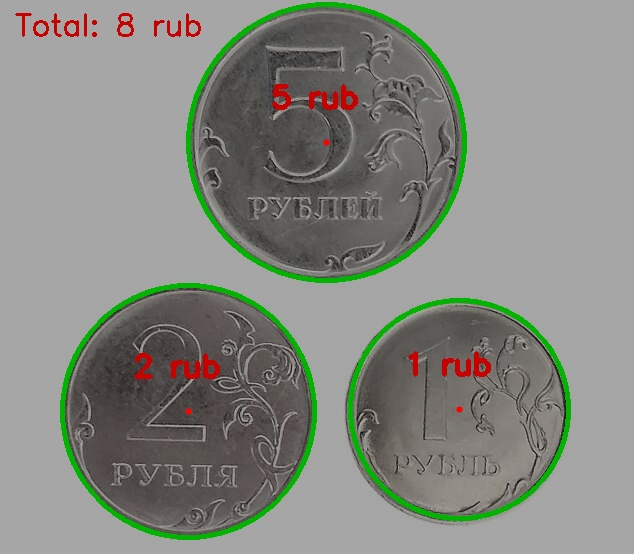

Сумма совпала с проверкой вручную: True


In [5]:
image = cv2.imread(str(folder / 'coins_1.png'))
if image is None:
    print('Не удалось открыть coins_1.png')
else:
    darker = cv2.convertScaleAbs(image, alpha=0.65, beta=0)
    dark_path = folder / 'coins_1_dark.png'
    cv2.imwrite(str(dark_path), darker)
    values = count_coins(dark_path, 116, 131, show_steps=False)
    if values is not None:
        print('Сумма совпала с проверкой вручную:', sum(values) == 8)

После уменьшения яркости программа тоже нашла 3 монеты и получила 8 рублей.

### Вывод

Программа находит монеты с помощью преобразования Хафа и считает сумму по их радиусам.
На двух снимках и на затемнённом варианте получилось по 8 рублей.
Для новых фотографий нужно подбирать границы радиусов и параметры поиска.
При другом масштабе, наклоне или наложении монет результат может быть неверным.